In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
data = pd.read_csv('/content/robot_inverse_kinematics_dataset.csv')

In [3]:
data.head()


,q1,q2,q3,q4,q5,q6,x,y,z
0,-1.51,-0.763,1.85,-0.817,0.9120,2.320,-0.0947,0.1500,0.301
1,-2.84,0.520,1.58,-1.270,-1.3900,0.617,0.1420,-0.1000,0.225
2,-1.23,0.695,1.22,-1.130,0.0343,6.270,-0.0833,0.2230,0.206
3,-1.99,1.060,1.74,-1.760,-1.2400,4.760,0.1350,-0.0314,0.370
4,1.05,0.836,1.34,-1.890,0.4840,4.380,-0.0560,-0.2290,0.260


In [4]:
data.tail()


,q1,q2,q3,q4,q5,q6,x,y,z
14995,0.314,-0.534,1.76,1.97,-0.699,3.87,-0.1130,-0.12800,0.257
14996,2.450,1.360,1.55,2.78,-0.321,5.31,0.0633,-0.03160,0.450
14997,2.620,1.410,1.56,2.54,1.060,5.87,0.1310,-0.16000,0.362
14998,-1.890,1.850,1.51,1.09,0.697,4.07,0.0829,-0.01600,0.441
14999,2.680,-1.790,1.79,2.62,1.590,2.64,-0.1570,-0.00369,0.254


In [5]:
data.shape

(15000, 9)

In [6]:
print(data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   q1      15000 non-null  float64
 1   q2      15000 non-null  float64
 2   q3      15000 non-null  float64
 3   q4      15000 non-null  float64
 4   q5      15000 non-null  float64
 5   q6      15000 non-null  float64
 6   x       15000 non-null  float64
 7   y       15000 non-null  float64
 8   z       15000 non-null  float64
dtypes: float64(9)
memory usage: 1.0 MB
None


In [7]:
data.describe()

,q1,q2,q3,q4,q5,q6,x,y,z
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,0.000855,-0.009156,1.572407,0.018612,-0.009395,3.143289,-0.005186,-0.000697,0.257294
std,1.655036,1.110602,0.201659,1.619865,1.211110,1.810345,0.102542,0.105618,0.112316
min,-2.880000,-1.920000,1.220000,-2.790000,-2.090000,0.000441,-0.290000,-0.298000,-0.020800
25%,-1.430000,-0.979250,1.400000,-1.380000,-1.060000,1.580000,-0.086900,-0.083700,0.165000
50%,0.006850,-0.010200,1.570000,0.038650,-0.021100,3.150000,-0.006940,-0.000201,0.256000
75%,1.420000,0.957000,1.750000,1.410000,1.040000,4.710000,0.075500,0.081900,0.343000
max,2.880000,1.920000,1.920000,2.790000,2.090000,6.280000,0.292000,0.297000,0.490000


In [8]:
data.min(numeric_only=True)

,0
q1,-2.880000
q2,-1.920000
q3,1.220000
q4,-2.790000
q5,-2.090000
q6,0.000441
x,-0.290000
y,-0.298000
z,-0.020800


In [9]:
data.max(numeric_only=True)

,0
q1,2.880
q2,1.920
q3,1.920
q4,2.790
q5,2.090
q6,6.280
x,0.292
y,0.297
z,0.490


In [10]:
data['x'].nunique()

2907

In [11]:
data['x'].unique()

array([-0.0947 ,  0.142  , -0.0833 , ..., -0.00107,  0.0224 , -0.0779 ],
      shape=(2907,))

In [12]:
data['y'].nunique()

2885

In [13]:
data['y'].unique()

array([ 0.15   , -0.1    ,  0.223  , ...,  0.00197, -0.0143 , -0.00369],
      shape=(2885,))

In [14]:
data['z'].nunique()

971

In [15]:
data['z'].unique()

array([ 3.01e-01,  2.25e-01,  2.06e-01,  3.70e-01,  2.60e-01,  2.45e-01,
        1.20e-01,  3.55e-01,  2.09e-01,  4.90e-02,  2.38e-01,  1.64e-01,
        3.82e-01,  4.27e-01,  2.86e-01,  3.40e-01,  2.82e-01,  2.27e-01,
        3.58e-01,  2.35e-01,  3.33e-01,  1.93e-01,  4.22e-01,  4.45e-01,
        1.91e-01,  1.48e-01,  4.21e-02,  3.31e-01,  1.10e-01,  2.64e-01,
        4.13e-01,  2.58e-01,  1.06e-01,  9.16e-02,  2.15e-01,  5.48e-02,
        2.23e-01,  4.46e-01,  3.00e-01,  1.70e-01,  4.47e-01,  1.16e-01,
        1.74e-01,  4.04e-01,  1.09e-01,  4.06e-01,  2.37e-01,  3.17e-01,
        1.54e-01,  1.65e-01,  1.61e-01,  3.03e-02,  3.20e-01,  3.84e-01,
        4.03e-01,  2.53e-01,  2.50e-01,  3.30e-01,  1.92e-01,  2.39e-01,
        3.53e-01,  2.04e-01,  1.72e-01,  3.18e-01,  3.05e-01,  2.40e-01,
        3.35e-01,  2.76e-01,  7.43e-02,  1.51e-01,  3.92e-01,  2.68e-01,
        2.99e-01,  3.12e-01,  2.22e-01,  2.47e-01,  3.62e-01,  3.07e-01,
        2.54e-01,  4.41e-01,  9.65e-02,  1.66e-01, 

In [16]:
data['q1'].nunique()

2516

In [17]:
data['q1'].unique()

array([-1.51  , -2.84  , -1.23  , ..., -0.0687,  0.396 ,  0.534 ],
      shape=(2516,))

In [18]:
data.isnull()

,q1,q2,q3,q4,q5,q6,x,y,z
0,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...
14995,False,False,False,False,False,False,False,False,False
14996,False,False,False,False,False,False,False,False,False
14997,False,False,False,False,False,False,False,False,False
14998,False,False,False,False,False,False,False,False,False


In [19]:
data.isnull().sum()

,0
q1,0
q2,0
q3,0
q4,0
q5,0
q6,0
x,0
y,0
z,0


In [20]:
data.duplicated().sum()

np.int64(0)

In [21]:
data = data.drop_duplicates()
data

,q1,q2,q3,q4,q5,q6,x,y,z
0,-1.510,-0.763,1.85,-0.817,0.9120,2.320,-0.0947,0.15000,0.301
1,-2.840,0.520,1.58,-1.270,-1.3900,0.617,0.1420,-0.10000,0.225
2,-1.230,0.695,1.22,-1.130,0.0343,6.270,-0.0833,0.22300,0.206
3,-1.990,1.060,1.74,-1.760,-1.2400,4.760,0.1350,-0.03140,0.370
4,1.050,0.836,1.34,-1.890,0.4840,4.380,-0.0560,-0.22900,0.260
...,...,...,...,...,...,...,...,...,...
14995,0.314,-0.534,1.76,1.970,-0.6990,3.870,-0.1130,-0.12800,0.257
14996,2.450,1.360,1.55,2.780,-0.3210,5.310,0.0633,-0.03160,0.450
14997,2.620,1.410,1.56,2.540,1.0600,5.870,0.1310,-0.16000,0.362
14998,-1.890,1.850,1.51,1.090,0.6970,4.070,0.0829,-0.01600,0.441


In [22]:
data.shape

(15000, 9)

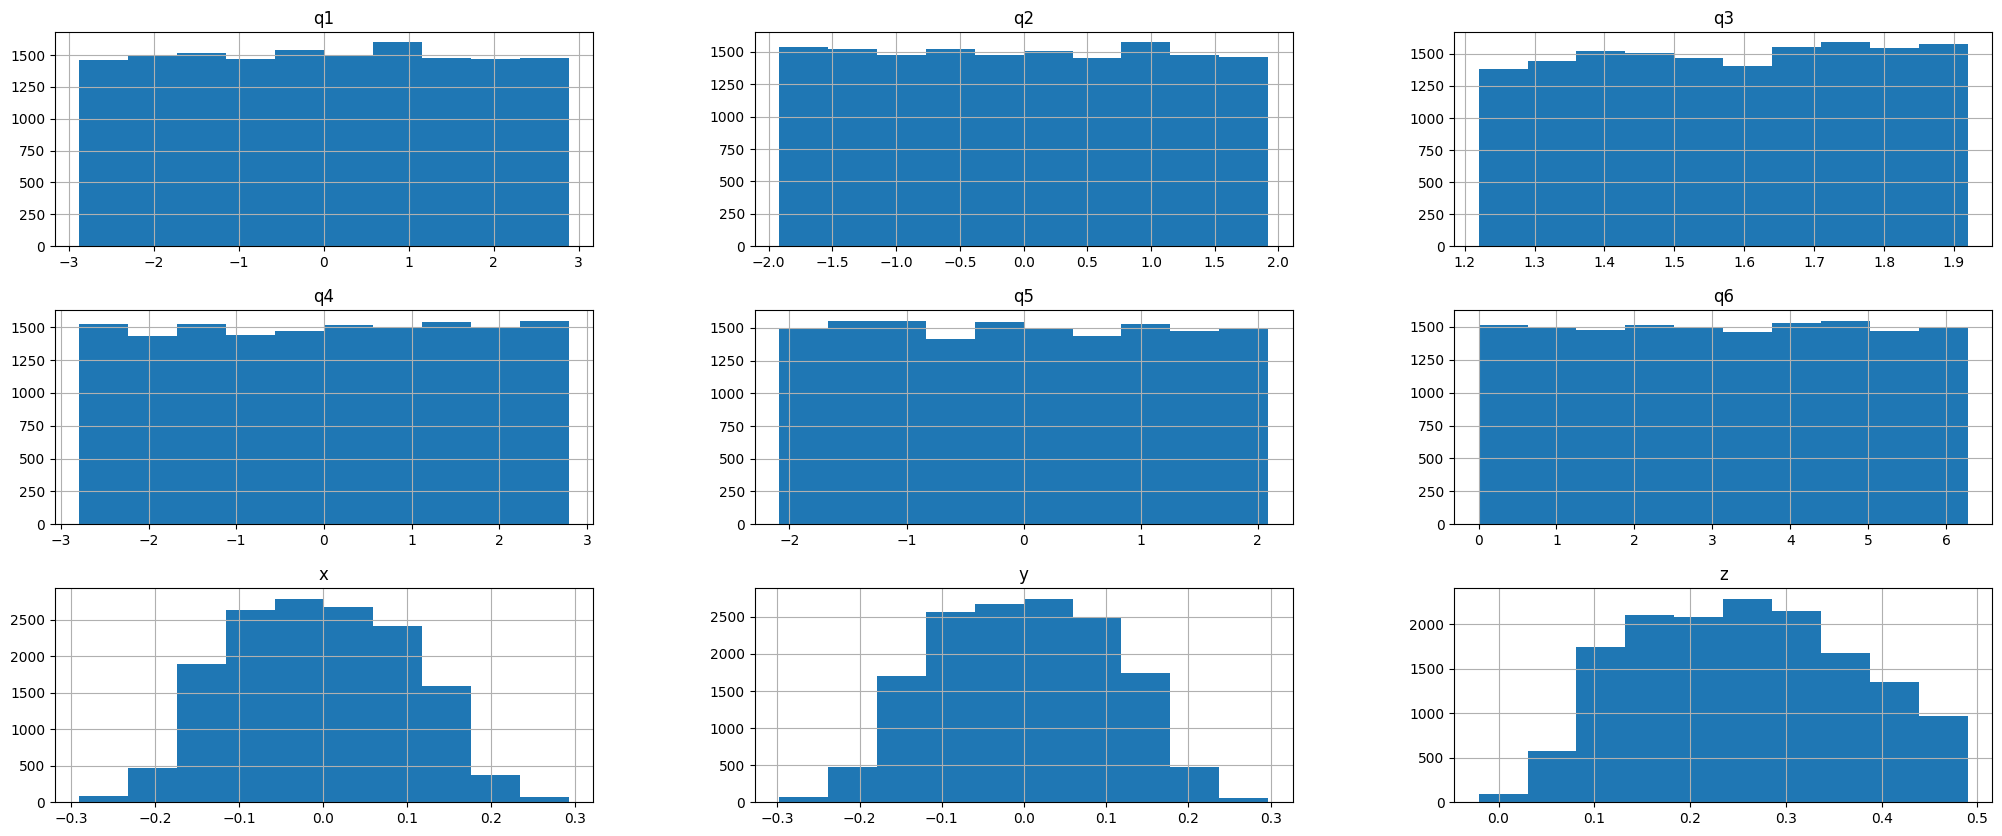

In [26]:
data.hist(figsize=(25,10))
plt.show()